# WP12 — EXPERIMENTAL_LOW_MEMORY_v1

Kullanıcı yalnız bu tek gerçek PDF açıklaması için daha düşük giriş limitlerini açıkça onayladı. Eski2,5GiB politika, smoke kayıtları ve önceki kaynaklı pilot hazırlığı değişmez. Bu notebook **sadece gerçek ölçüm ve hazır betiği belgeler; inference/API yoktur**. Normal kullanıcı PowerShell'inde S01-R1 bekleniyor. Ölçümler çalışabilirlik veya güvenlik garantisi değildir.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists(): ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP12/experimental_low_memory_v1'
F=ROOT/'reports/figures/WP12/experimental_low_memory_v1'
def read(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
p=read(ROOT/'configs/WP12_EXPERIMENTAL_LOW_MEMORY_v1.json');m=read(Q/'current_measurements.json')
checks=read(Q/'preparation_checks.json')
pd.set_option('display.max_colwidth',600)

display(pd.DataFrame([{'politika':p['version'],'RAM_GiB':p['RAM_floor_bytes']/2**30,
 'VRAM_GiB':p['GPU_floor_MiB']/1024,'commit_GiB':p['commit_floor_bytes']/2**30,
 'runtime_RAM_GiB':p['runtime_RAM_floor_bytes']/2**30,'runtime_commit_GiB':p['runtime_commit_floor_bytes']/2**30,
 'HTTP_timeout_s':p['HTTP_timeout_seconds'],'otomatik_tekrar':p['automatic_retry']}]))
display(pd.DataFrame([m['memory']]).assign(GPU_free_MiB=m['GPU']['free_MiB']))


,politika,RAM_GiB,VRAM_GiB,commit_GiB,runtime_RAM_GiB,runtime_commit_GiB,HTTP_timeout_s,otomatik_tekrar
0,EXPERIMENTAL_LOW_MEMORY_v1,1.5,1.0,3.0,0.75,1.0,60,False


,low_memory_notification,at,load_percent,total_bytes,commit_available_bytes,available_bytes,GPU_free_MiB
0,False,2026-11-08T06:41:41.2885997+03:00,72,7968415744,12209291264,2216243200,3935


**Yorum:** Başlangıç≥1,5GiB RAM,≥1GiB VRAM,≥3GiB commit ve Windows düşük bellek sinyali=false. Commit bir fiziksel RAM rezervi değildir. Çalışmada RAM<0,75GiB, commit<1GiB veya OS düşük bellek sinyali varsa kayıt ve HTTP istemci iptali; sunucunun anında durması garanti edilmez. Eksik ölçümde devam edilmez. Eski2,5GiB RAM kapısı önceki politikalarda hâlâ geçerlidir.

## Gerçek ölçüm ve beş kararlı örnek

,commit_available_bytes,at,load_percent,low_memory_notification,available_bytes,total_bytes
0,12278472704,2026-11-08T06:43:43.0506054+03:00,72,False,2177646592,7968415744
1,12282322944,2026-11-08T06:43:44.0807660+03:00,72,False,2177601536,7968415744
2,12281520128,2026-11-08T06:43:45.0865783+03:00,72,False,2176778240,7968415744
3,12284227584,2026-11-08T06:43:46.0904127+03:00,72,False,2179387392,7968415744
4,12285706240,2026-11-08T06:43:47.0998251+03:00,72,False,2181505024,7968415744


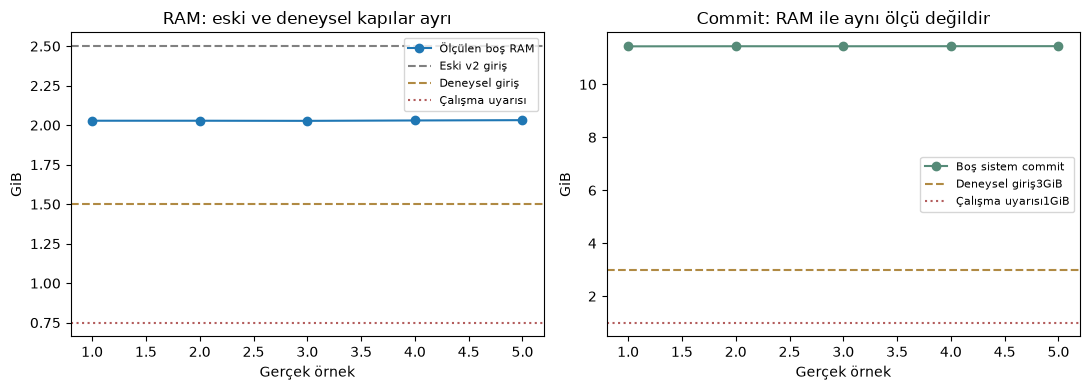

,gerçek_kayıt
scope,PREPARATION_ONLY_NO_INFERENCE
memory_policy,EXPERIMENTAL_LOW_MEMORY_v1
measurement_at,2026-11-08T06:41:41.2885997+03:00
initial_gate_passed_at_observation,True
all_5_host_commit_OS_samples_passed,True
GPU_measurement_single_snapshot_not_runtime_peak,True
available_RAM_GiB,2.064037
available_commit_GiB,11.370789
GPU_free_MiB,3935
OS_low_memory_notification,False


In [2]:

samples=pd.DataFrame(read(Q/'read_only_stability_samples.json')['memory'])
display(samples)
fig,axes=plt.subplots(1,2,figsize=(11,4))
ram=samples.available_bytes/2**30;commit=samples.commit_available_bytes/2**30
axes[0].plot(range(1,6),ram,marker='o',label='Ölçülen boş RAM')
axes[0].axhline(2.5,color='gray',ls='--',label='Eski v2 giriş')
axes[0].axhline(1.5,color='#b08a43',ls='--',label='Deneysel giriş')
axes[0].axhline(.75,color='#b35c5c',ls=':',label='Çalışma uyarısı')
axes[0].set(xlabel='Gerçek örnek',ylabel='GiB',title='RAM: eski ve deneysel kapılar ayrı');axes[0].legend(fontsize=8)
axes[1].plot(range(1,6),commit,marker='o',color='#568b78',label='Boş sistem commit')
axes[1].axhline(3,color='#b08a43',ls='--',label='Deneysel giriş3GiB')
axes[1].axhline(1,color='#b35c5c',ls=':',label='Çalışma uyarısı1GiB')
axes[1].set(xlabel='Gerçek örnek',ylabel='GiB',title='Commit: RAM ile aynı ölçü değildir');axes[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(F/'01_actual_memory_samples_and_separate_thresholds.png',dpi=160);plt.show()
display(pd.DataFrame([checks]).T.rename(columns={0:'gerçek_kayıt'}))


**Yorum:** Beş örneğin RAM/commit/OS koşulları geçti; GPU ayrı anlık3935MiB ölçümüdür, beş eşzamanlı GPU ölçümü veya tepe değildir. Bu hazırlıkta AppContainer=true olduğu için API'ye hiç başvurulmadı. Kullanıcı betiği her kapıyı yeniden ölçer ve AppContainer'da metadata isteğinden bile önce durur.

Model dosyası yaklaşık769MiB; önceki gerçek GGUF metadatasıyla26 katman,1 KVhead,256 key/256value ve2048context için varsayımsal tam FP16 KV52MiB. Runtime/aktivasyon/sürücü/CPU-GPU kopyaları buna dahil değildir. Bunlar resident/peak ölçümü değildir;1GiB GPU veya1,5GiB RAM modelin sığacağını garanti etmez.

## Değişmeyen gerçek kaynak ve yöntem

In [3]:

ctx=read(ROOT/'reports/qa/WP12/source_single_case_v1/package/context.json')
display(pd.DataFrame([ctx['scenario']])[['scenario_id','question_tr','acceptance_criteria_tr']])
display(pd.DataFrame(ctx['sources'])[['physical_page','scope','kind','quote_id','quote']])
display(pd.DataFrame([{'tam_prompt_token':919,'giriş_limiti':1536,'çıktı':384,'güvenlik':128,
 'context':2048,'gerçek_üretim':0,'semantik_inceleme':'GERÇEK_YANIT_BEKLENİYOR','otomatik_yayın':False}]))


,scenario_id,question_tr,acceptance_criteria_tr
0,S01,Ürün ve formülasyon kaynakta nasıl tanımlanıyor?,Ürün beyanını ana ilaç kimliğine eşdeğerlik iddiasına dönüştürme.


,physical_page,scope,kind,quote_id,quote
0,1,product_identity,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n"
1,6,product_identity,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n"


,tam_prompt_token,giriş_limiti,çıktı,güvenlik,context,gerçek_üretim,semantik_inceleme,otomatik_yayın
0,919,1536,384,128,2048,0,GERÇEK_YANIT_BEKLENİYOR,False


**Yorum:** S01-R1 Erythromycin ürün/formülasyon sorusudur; fiziksel sayfa1 ve6'nın iki tam alıntısı537 karakterdir. Frozen senaryo/soru/kabul kriteri, model digest, prompt, JSON Schema ve generation ayarları değişmedi. Yalnız ayrı bellek politikası ve ölçüm koşulları eklendi.919 token önceki gerçek sözlük-only hesabıdır; kullanıcı isteğinden önce aynı tokenizer ile yeniden sayılır. Tam alıntı/bağlam sığmazsa CONTEXT_BUDGET; kesme/fallback yok.

25 yeni deneysel test ve24 mevcut kaynak sözleşmesi testi geçti. PS5.1 parser0hata, tek generation çağrı noktası. Eksik ölçüm, düşük RAM/GPU/commit ve OS basıncı sınandı; hiç optimizer/LLM inference yapılmadı. Geçerli JSON/quote-ID semantik başarı değildir. `reported_in_PDF` ile `predicted_by_GNN` ayrıdır; sonuncu NOT_REQUESTED/null kalır. Gerçek açıklama ilk kullanıcı çıktısından sonra insan tarafından incelenecek.57 çağrı, otomatik tekrar/yayın ve WP13 kapalıdır.